## Read embeddings

In [487]:
import pandas as pd
import pandas as pd
# MODELS PARAMS
## PARAMETERS
RUNS = 10
total_splits = 1

MODELS_DESCRIPTIONS = {
    "single_allele_imbalanced": {
        "path": "experiment_results/alleles_with_groups_single_allele_imbalanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10],
    },
    "single_allele_balanced": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10]
    },
    "multiple_allele_balanced": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10, 11, 12]
    },
    "multiple_allele_imbalanced": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_imbalanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10]
    },
    "mix_of_alleles":
        {
            "path": "experiment_results/alleles_with_groups/",
            "states": 25,
            "params_string": "5-min_iters",
            "alleles": ['HLA-A*01:01', 'HLA-A*03:01'],
            "target_lengths": [9, 10],
            "combination_size":2
        },
    # "mix_of_alleles_balanced":
    # {
    #     "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
    #     "path": "experiment_results/alleles_with_groups_balanced/",
    #     "states": 25,
    #     "params_string": "5-min_iters",
    #     "target_lengths": [9, 10]
    # }
}

# selected_model = MODELS_DESCRIPTIONS["multiple_allele_imbalanced"]
selected_model = MODELS_DESCRIPTIONS["multiple_allele_balanced"]
# selected_model = MODELS_DESCRIPTIONS["single_allele_imbalanced"]
# selected_model = MODELS_DESCRIPTIONS["single_allele_balanced"]


In [488]:
#Selected combination
# combination = ('HLA-A*01:01', 'HLA-A*02:01')
combination = ('HLA-A*01:01', 'HLA-A*03:01')

# combination = ('HLA-A*02:01', 'HLA-A*03:01')
# combination = ('HLA-A*01:01','HLA-A*02:01', 'HLA-A*03:01')

# combination = ('HLA-A*01:01',)
# combination = ('HLA-A*03:01',)
# combination = ('HLA-A*02:01',)

In [489]:
combination

('HLA-A*01:01', 'HLA-A*03:01')

In [490]:
for allele_name in combination:
    assert allele_name in selected_model['alleles'], f"{allele_name} not in "
selected_alleles = list(combination)


states = selected_model['states']
TARGET_LENGTHS = selected_model['target_lengths']
selected_combination = "+".join(selected_alleles).replace('-', '_').replace('*', '_').replace(':', '_')
selected_model_split = 0 # should match to data split (if original train/test used) in order to have true test case
selected_model_run = "combined"
target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])

In [491]:
mixed_model_bw =f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'
mixed_model_bwv = f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}_plus_viterbi'
mixed_model_v = f'{selected_model_run}_run-{target_length_string}-{states}-st-viterbi-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'

name_to_model_root = dict()
name_to_model_root[mixed_model_bw] = selected_model['path']
name_to_model_root[mixed_model_bwv] = selected_model['path']
name_to_model_root[mixed_model_v] = selected_model['path']

In [492]:
def load_embeddings(model):
    print(f"model {model}")
    TARGET_PATH_TO_FILES = name_to_model_root[model] + model
    # Train 
    train_df =  pd.read_csv("{}/train_embedding.csv".format(TARGET_PATH_TO_FILES),sep=";",index_col=0)
    # Test 
    test_df =  pd.read_csv("{}/test_embedding.csv".format(TARGET_PATH_TO_FILES),sep=";",index_col=0)

    # paths_df['path'] = paths_df['path'].apply(pd.eval)
    # paths_df['path'] = paths_df['path'].astype(list)
    return  train_df, test_df


In [602]:
%%time
per_model_type_train_embeddings = dict()
per_model_type_test_embeddings = dict()
# BW
train_df, test_df = load_embeddings(mixed_model_bw)
per_model_type_train_embeddings['bw'] = train_df
per_model_type_test_embeddings['bw'] = test_df
# BWV
train_df, test_df = load_embeddings(mixed_model_bwv)
per_model_type_train_embeddings['bwv'] = train_df
per_model_type_test_embeddings['bwv'] = test_df
# V
train_df, test_df = load_embeddings(mixed_model_v)
per_model_type_train_embeddings['v'] = train_df
per_model_type_test_embeddings['v'] = test_df

model combined_run-9-10-11-12-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
model combined_run-9-10-11-12-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi
model combined_run-9-10-11-12-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Wall time: 1min 26s


# Scanpy

In [603]:
import scanpy as sc
import anndata as ad
import numpy as np

In [667]:
target_df = per_model_type_train_embeddings['v'].copy()


## Select target df for analysis

In [668]:
TARGET_LENGTH = 10


target_df = target_df[target_df.peptide.str.len() == TARGET_LENGTH]


if TARGET_LENGTH == 10:
    target_df = target_df[target_df.allele.isin(['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*03:01_L1', 'HLA-A*03:01_R1', 'HLA-A*01:01_R1', 'HLA-A*01:01_L1', 'HLA-A*03:01_imm', 'HLA-A*01:01_imm'])]
if TARGET_LENGTH == 11:
    target_df = target_df[target_df.allele.isin([
        'HLA-A*01:01', 'HLA-A*03:01', 
        # 'HLA-A*03:01_L2', 
        'HLA-A*01:01_R2', 
        # 'HLA-A*01:01_L2', 
        # 'HLA-A*01:01_LR1', 
        # 'HLA-A*03:01_LR1'
        'HLA-A*03:01_R2',
        'HLA-A*03:01_imm', 'HLA-A*01:01_imm'])]



In [669]:
target_df

,0,1,2,3,4,5,6,7,8,9,...,4992,4993,4994,4995,4996,4997,4998,4999,allele,peptide
2,-69.232233,-97.725031,NaN,NaN,NaN,NaN,-100.541601,NaN,-84.728584,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-128.347439,NaN,HLA-A*03:01,AMENLKAMLY
5,-106.070486,-93.144184,NaN,NaN,NaN,NaN,-100.696793,NaN,-106.353388,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-88.428829,NaN,HLA-A*01:01_L1,DCTDPYSQMV
7,-102.242951,-92.576605,NaN,NaN,NaN,NaN,-95.411452,NaN,-69.977561,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-109.611815,NaN,HLA-A*03:01_R1,IQFSMKLLYQ
14,-115.349752,-101.946201,NaN,NaN,NaN,NaN,-69.108517,NaN,-104.030111,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-100.568879,NaN,HLA-A*03:01_L1,ATFYAEFPKK
17,-78.987029,-97.096177,NaN,NaN,NaN,NaN,-102.255528,NaN,-87.168899,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-120.551229,NaN,HLA-A*01:01,KSDIPMDLFD
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30886,-79.539705,-56.621505,NaN,NaN,NaN,NaN,-94.016243,NaN,-97.596032,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-118.890889,NaN,HLA-A*01:01,YSDLNTQRPY
30894,-89.683948,-92.507352,NaN,NaN,NaN,NaN,-76.006773,NaN,-96.863518,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-127.346336,NaN,HLA-A*01:01_R1,FIDGISLGLK
30895,-75.874038,-90.199439,NaN,NaN,NaN,NaN,-96.080777,NaN,-98.566941,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-109.786646,NaN,HLA-A*03:01_L1,PLSARHASGK
30896,-85.431649,-51.917125,NaN,NaN,NaN,NaN,-121.491423,NaN,-94.739270,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-122.645038,NaN,HLA-A*01:01,TTDPNVRWEY


In [670]:
# ##

target_df = target_df[target_df['peptide'].isin(selected_peptides['peptide'].values)]
# ##

In [671]:
len(target_df)

1615

### Filter empty columns

In [672]:
target_df.replace([-np.inf], np.nan, inplace=True)
target_df = target_df.dropna(axis=1, how='all').copy()

D:\Tools\Python\Anaconda\envs\pomegranate\lib\site-packages\pandas\core\frame.py:5238: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  return super().replace(


In [673]:
target_df

,0,1,6,8,11,12,15,22,25,30,...,4938,4941,4942,4944,4950,4952,4963,4998,allele,peptide
5,-106.070486,-93.144184,-100.696793,-106.353388,-90.332560,-82.488976,-92.211372,-85.233400,-95.354552,-75.749251,...,-100.895128,-80.570321,-114.681784,-122.243527,-100.683872,-112.316678,-108.941441,-88.428829,HLA-A*01:01_L1,DCTDPYSQMV
7,-102.242951,-92.576605,-95.411452,-69.977561,-117.260549,-99.690780,-126.095146,-93.139915,-96.955608,-104.804988,...,-113.028785,-85.071345,-121.863476,-115.428653,-94.375120,-94.802000,-121.751331,-109.611815,HLA-A*03:01_R1,IQFSMKLLYQ
17,-78.987029,-97.096177,-102.255528,-87.168899,-105.441450,-88.081283,-95.177195,-75.853758,-100.159193,-122.362381,...,-95.437988,-98.046273,-105.941839,-102.764861,-127.211429,-102.021107,-122.912713,-120.551229,HLA-A*01:01,KSDIPMDLFD
20,-77.977269,-100.526928,-95.312247,-106.176374,-109.747915,-119.377933,-107.989344,-110.874403,-100.969897,-96.875412,...,-113.248993,-131.499688,-120.556031,-103.802229,-117.392442,-114.153308,-102.456730,-107.060474,HLA-A*01:01,YPEEVSSMVL
21,-97.459905,-77.576288,-98.407477,-84.932177,-84.937944,-107.405253,-104.094602,-88.862113,-99.118508,-81.959782,...,-102.038065,-85.306632,-84.926628,-111.696330,-108.005318,-121.111486,-113.453041,-117.136639,HLA-A*03:01_R1,TVLKPGNSKM
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30850,-72.884694,-71.707569,-88.581543,-76.980397,-88.922493,-61.395794,-90.101959,-91.205850,-96.839758,-70.761636,...,-114.734969,-113.814055,-86.894893,-95.598476,-112.584250,-84.262558,-113.458977,-121.220966,HLA-A*03:01_R1,VVAALRASYP
30856,-94.132376,-91.392716,-89.237048,-107.206352,-119.700141,-109.438464,-100.177508,-109.553151,-111.490503,-101.006108,...,-103.969770,-114.329560,-92.100477,-120.675345,-110.836463,-129.382937,-114.368135,-108.498363,HLA-A*03:01,SMQGAVDINR
30862,-77.552175,-80.663351,-83.111257,-97.719105,-93.615504,-69.986205,-63.840160,-72.918031,-101.081890,-86.447204,...,-86.409899,-118.769706,-104.666331,-91.389308,-128.740656,-127.476186,-105.541114,-128.142599,HLA-A*01:01,TSDKGRFYAF
30894,-89.683948,-92.507352,-76.006773,-96.863518,-97.512656,-104.134636,-117.137085,-107.241005,-107.970593,-96.551069,...,-103.944921,-107.908356,-116.605336,-101.071057,-128.740656,-111.390478,-121.762378,-127.346336,HLA-A*01:01_R1,FIDGISLGLK


In [674]:
target_df.index = target_df['peptide'].values

In [675]:
dropped_columns = target_df.drop(columns=['allele', 'peptide']).copy()
transposed = dropped_columns.T.copy()

In [676]:
target_df['allele'].value_counts()

HLA-A*01:01_R1     410
HLA-A*01:01        377
HLA-A*03:01_R1     299
HLA-A*03:01        264
HLA-A*01:01_L1     148
HLA-A*03:01_L1     115
HLA-A*03:01_imm      2
Name: allele, dtype: int64

## Code to deal with missing values

In [677]:


# from sklearn.experimental import enable_iterative_imputer
# from sklearn.impute import IterativeImputer
# imp = IterativeImputer(max_iter=10, random_state=0, verbose=2)
# X = np.exp(target_df.drop(columns=['allele', 'peptide']).values)
# X = imp.fit_transform(X)

In [678]:
## Try log prob normalization 

In [679]:
## Was trying to normalize logprobs to see as (from 0 to 1)
# maximums = np.nanmax(X, axis=0)
# X_converted = np.exp(X - maximums)
# sums = np.nansum(np.sort(X_converted, axis=0), axis=0)
# X_converted = X_converted / sums


In [680]:
# from sklearn.impute import SimpleImputer
# imp_mean = SimpleImputer(missing_values=np.nan, strategy='mean')

# X = -target_df.drop(columns=['allele', 'peptide']).values
# # X = np.exp(target_df.drop(columns=['allele', 'peptide']).values)
# X = imp_mean.fit_transform(X)

# DO Scanpy

In [681]:
obs = pd.DataFrame({"peptide": target_df.index.values, "allele": target_df['allele'].values, "length": target_df.index.str.len().values})
var = pd.DataFrame({"path":target_df.columns.drop(['allele', 'peptide'])})
# X = np.exp(target_df.drop(columns=['allele', 'peptide']).values/ TARGET_LENGTH)
X = -target_df.drop(columns=['allele', 'peptide']).values

In [682]:
adata = ad.AnnData(X, obs=obs, var=var, dtype='float')

D:\Tools\Python\Anaconda\envs\pomegranate\lib\site-packages\anndata\_core\anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [683]:
target_df

,0,1,6,8,11,12,15,22,25,30,...,4938,4941,4942,4944,4950,4952,4963,4998,allele,peptide
DCTDPYSQMV,-106.070486,-93.144184,-100.696793,-106.353388,-90.332560,-82.488976,-92.211372,-85.233400,-95.354552,-75.749251,...,-100.895128,-80.570321,-114.681784,-122.243527,-100.683872,-112.316678,-108.941441,-88.428829,HLA-A*01:01_L1,DCTDPYSQMV
IQFSMKLLYQ,-102.242951,-92.576605,-95.411452,-69.977561,-117.260549,-99.690780,-126.095146,-93.139915,-96.955608,-104.804988,...,-113.028785,-85.071345,-121.863476,-115.428653,-94.375120,-94.802000,-121.751331,-109.611815,HLA-A*03:01_R1,IQFSMKLLYQ
KSDIPMDLFD,-78.987029,-97.096177,-102.255528,-87.168899,-105.441450,-88.081283,-95.177195,-75.853758,-100.159193,-122.362381,...,-95.437988,-98.046273,-105.941839,-102.764861,-127.211429,-102.021107,-122.912713,-120.551229,HLA-A*01:01,KSDIPMDLFD
YPEEVSSMVL,-77.977269,-100.526928,-95.312247,-106.176374,-109.747915,-119.377933,-107.989344,-110.874403,-100.969897,-96.875412,...,-113.248993,-131.499688,-120.556031,-103.802229,-117.392442,-114.153308,-102.456730,-107.060474,HLA-A*01:01,YPEEVSSMVL
TVLKPGNSKM,-97.459905,-77.576288,-98.407477,-84.932177,-84.937944,-107.405253,-104.094602,-88.862113,-99.118508,-81.959782,...,-102.038065,-85.306632,-84.926628,-111.696330,-108.005318,-121.111486,-113.453041,-117.136639,HLA-A*03:01_R1,TVLKPGNSKM
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
VVAALRASYP,-72.884694,-71.707569,-88.581543,-76.980397,-88.922493,-61.395794,-90.101959,-91.205850,-96.839758,-70.761636,...,-114.734969,-113.814055,-86.894893,-95.598476,-112.584250,-84.262558,-113.458977,-121.220966,HLA-A*03:01_R1,VVAALRASYP
SMQGAVDINR,-94.132376,-91.392716,-89.237048,-107.206352,-119.700141,-109.438464,-100.177508,-109.553151,-111.490503,-101.006108,...,-103.969770,-114.329560,-92.100477,-120.675345,-110.836463,-129.382937,-114.368135,-108.498363,HLA-A*03:01,SMQGAVDINR
TSDKGRFYAF,-77.552175,-80.663351,-83.111257,-97.719105,-93.615504,-69.986205,-63.840160,-72.918031,-101.081890,-86.447204,...,-86.409899,-118.769706,-104.666331,-91.389308,-128.740656,-127.476186,-105.541114,-128.142599,HLA-A*01:01,TSDKGRFYAF
FIDGISLGLK,-89.683948,-92.507352,-76.006773,-96.863518,-97.512656,-104.134636,-117.137085,-107.241005,-107.970593,-96.551069,...,-103.944921,-107.908356,-116.605336,-101.071057,-128.740656,-111.390478,-121.762378,-127.346336,HLA-A*01:01_R1,FIDGISLGLK


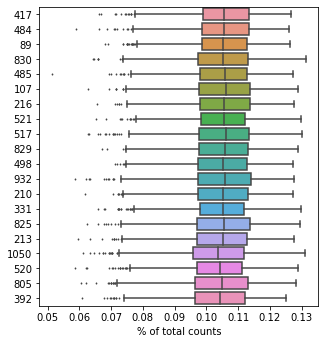

In [684]:
sc.pl.highest_expr_genes(adata, n_top=20, )

In [685]:
target_df

,0,1,6,8,11,12,15,22,25,30,...,4938,4941,4942,4944,4950,4952,4963,4998,allele,peptide
DCTDPYSQMV,-106.070486,-93.144184,-100.696793,-106.353388,-90.332560,-82.488976,-92.211372,-85.233400,-95.354552,-75.749251,...,-100.895128,-80.570321,-114.681784,-122.243527,-100.683872,-112.316678,-108.941441,-88.428829,HLA-A*01:01_L1,DCTDPYSQMV
IQFSMKLLYQ,-102.242951,-92.576605,-95.411452,-69.977561,-117.260549,-99.690780,-126.095146,-93.139915,-96.955608,-104.804988,...,-113.028785,-85.071345,-121.863476,-115.428653,-94.375120,-94.802000,-121.751331,-109.611815,HLA-A*03:01_R1,IQFSMKLLYQ
KSDIPMDLFD,-78.987029,-97.096177,-102.255528,-87.168899,-105.441450,-88.081283,-95.177195,-75.853758,-100.159193,-122.362381,...,-95.437988,-98.046273,-105.941839,-102.764861,-127.211429,-102.021107,-122.912713,-120.551229,HLA-A*01:01,KSDIPMDLFD
YPEEVSSMVL,-77.977269,-100.526928,-95.312247,-106.176374,-109.747915,-119.377933,-107.989344,-110.874403,-100.969897,-96.875412,...,-113.248993,-131.499688,-120.556031,-103.802229,-117.392442,-114.153308,-102.456730,-107.060474,HLA-A*01:01,YPEEVSSMVL
TVLKPGNSKM,-97.459905,-77.576288,-98.407477,-84.932177,-84.937944,-107.405253,-104.094602,-88.862113,-99.118508,-81.959782,...,-102.038065,-85.306632,-84.926628,-111.696330,-108.005318,-121.111486,-113.453041,-117.136639,HLA-A*03:01_R1,TVLKPGNSKM
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
VVAALRASYP,-72.884694,-71.707569,-88.581543,-76.980397,-88.922493,-61.395794,-90.101959,-91.205850,-96.839758,-70.761636,...,-114.734969,-113.814055,-86.894893,-95.598476,-112.584250,-84.262558,-113.458977,-121.220966,HLA-A*03:01_R1,VVAALRASYP
SMQGAVDINR,-94.132376,-91.392716,-89.237048,-107.206352,-119.700141,-109.438464,-100.177508,-109.553151,-111.490503,-101.006108,...,-103.969770,-114.329560,-92.100477,-120.675345,-110.836463,-129.382937,-114.368135,-108.498363,HLA-A*03:01,SMQGAVDINR
TSDKGRFYAF,-77.552175,-80.663351,-83.111257,-97.719105,-93.615504,-69.986205,-63.840160,-72.918031,-101.081890,-86.447204,...,-86.409899,-118.769706,-104.666331,-91.389308,-128.740656,-127.476186,-105.541114,-128.142599,HLA-A*01:01,TSDKGRFYAF
FIDGISLGLK,-89.683948,-92.507352,-76.006773,-96.863518,-97.512656,-104.134636,-117.137085,-107.241005,-107.970593,-96.551069,...,-103.944921,-107.908356,-116.605336,-101.071057,-128.740656,-111.390478,-121.762378,-127.346336,HLA-A*01:01_R1,FIDGISLGLK


## 1. Normalize

In [686]:
# sc.pp.scale(adata)

In [687]:
adata.X

array([[106.07048553,  93.14418424, 100.69679285, ..., 112.31667836,
        108.9414409 ,  88.42882908],
       [102.2429512 ,  92.57660468,  95.41145207, ...,  94.80200024,
        121.75133058, 109.61181496],
       [ 78.98702876,  97.09617685, 102.25552849, ..., 102.02110685,
        122.91271271, 120.55122922],
       ...,
       [ 77.55217492,  80.66335101,  83.11125696, ..., 127.47618626,
        105.54111367, 128.14259851],
       [ 89.68394807,  92.50735153,  76.00677283, ..., 111.3904784 ,
        121.76237845, 127.34633569],
       [102.14261283,  99.64841175, 108.33607684, ..., 110.32802918,
        101.59074231, 109.74957986]])

In [688]:
sc.pp.normalize_total(adata) # Total-count normalize (library-size correct) the data matrix X to 10,000 reads per cell, so that counts become comparable among cells.
sc.pp.log1p(adata) # log-normalization

In [689]:
adata.X

array([[4.6539706 , 4.52533624, 4.60248883, ..., 4.71065936, 4.68042626,
        4.473963  ],
       [4.62234992, 4.52406036, 4.55390024, ..., 4.5475598 , 4.79540249,
        4.6912822 ],
       [4.37616614, 4.5802367 , 4.63149213, ..., 4.62921937, 4.8138534 ,
        4.79461274],
       ...,
       [4.35752466, 4.39636386, 4.42589669, ..., 4.84947382, 4.66227136,
        4.85464721],
       [4.54501027, 4.5756824 , 4.38145014, ..., 4.75968865, 4.8479881 ,
        4.89248309],
       [4.63138017, 4.60690207, 4.68969133, ..., 4.70774519, 4.62601549,
        4.70253597]])

## 2. Highly variable features

In [690]:
import matplotlib.pyplot as plt
# sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
# sc.pl.highly_variable_genes(adata, show=False) # can not scale only x

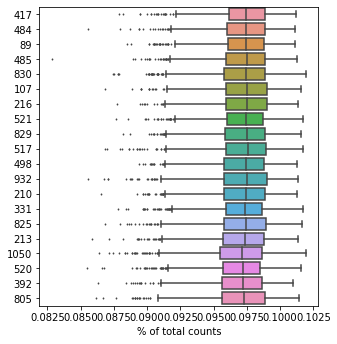

In [691]:
sc.pl.highest_expr_genes(adata, n_top=20, )

## 3. PCA

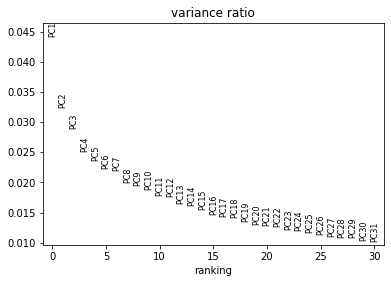

In [692]:
sc.tl.pca(adata, svd_solver='arpack')
sc.pl.pca_variance_ratio(adata)

## Regress out PC1

In [693]:
#not doing now
# adata.obsm['X_pca'][:, 0:1]  = 0
# adata.varm['PCs'][:, 0:1] = 0
# adata.uns['pca']['variance_ratio'][0:1] = 0
# adata.uns['pca']['variance'][0:1] = 0
# adata.obsm['X_pca']

In [694]:
# sc.pl.pca_variance_ratio(adata)

In [695]:
#Some plots for PCA distributions
#from itertools import product
#sc.pl.pca(adata, color='length',dimensions=list(product(range(5), repeat=2)), ncols=5 )
#sc.pl.pca(adata, color='length',dimensions=[(i,i) for i in range(20)], ncols=5 )

In [696]:
# import seaborn as sns
# n=10
# fig, axes = plt.subplots(nrows=n//5, ncols=5, figsize=(25, 5*n/5))

# for i,ax in enumerate(axes.flatten()):
#     df = pd.DataFrame({f"PC_{i}":adata.obsm['X_pca'][:,i], "length" : adata.obs['length'].values })
#     sns.histplot(df, x=f"PC_{i}", hue='length', ax=ax )

## 4. Neighborhood graph and umap

In [697]:
from itertools import product
import seaborn as sns
import matplotlib.pyplot as plt

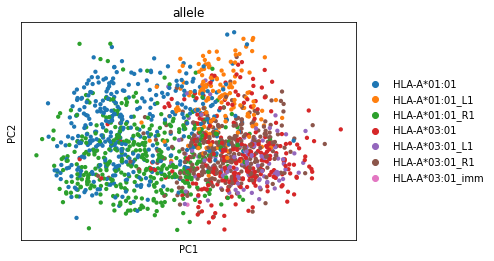

In [698]:
sc.pl.pca(adata, color='allele')

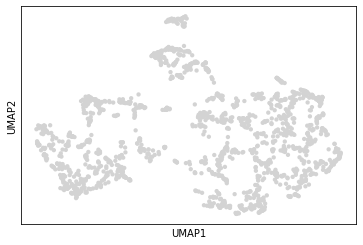

In [746]:
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=5, metric="euclidean")
sc.tl.umap(adata, min_dist=0.001, n_components=2)
sc.pl.umap(adata)

## 5.  Cell clusters

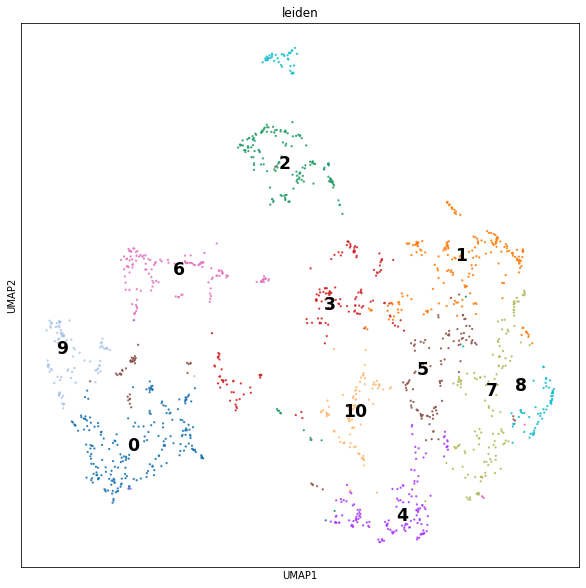

In [747]:
from matplotlib.pyplot import rc_context
with rc_context({'figure.figsize': (10, 10)}):
    sc.tl.leiden(adata, resolution=0.6)
    sc.tl.louvain(adata, resolution=0.3)
    sc.pl.umap(adata, color='leiden', s=20, 
               # add_outline=True, 
               legend_loc='on data',
              legend_fontsize='xx-large',
              legend_fontweight='bold', 
               alpha=0.9)
    # sc.pl.umap(adata, color='louvain', s=20)


<AxesSubplot:xlabel='0', ylabel='1'>

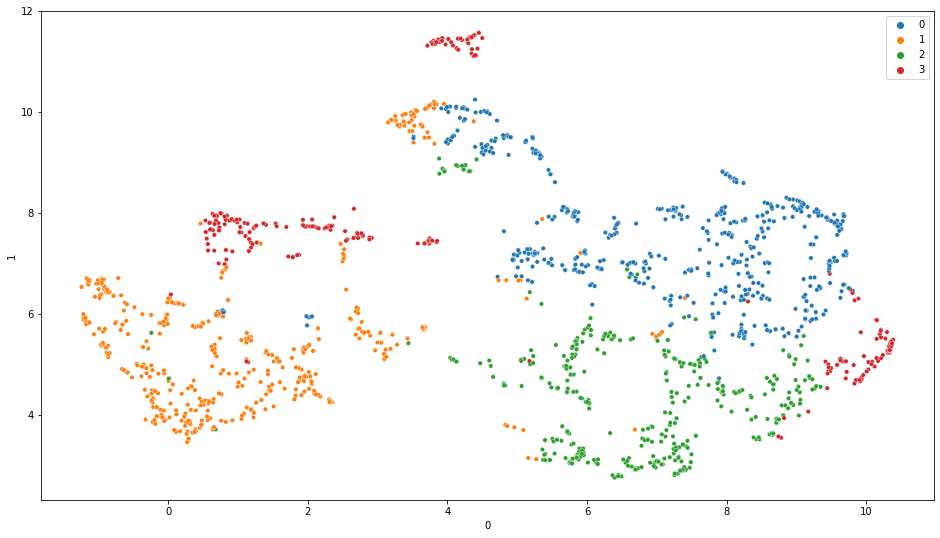

In [748]:
plt.figure(figsize=(16,9))
df = pd.DataFrame(adata.obsm['X_umap'])
sns.scatterplot(data=df, x=0, y=1,s=20, hue=adata.obs['louvain'].values)



## 6. Color by allele

In [749]:
adata_copy = adata_copy = adata[~adata.obs['allele'].str.contains('imm')]

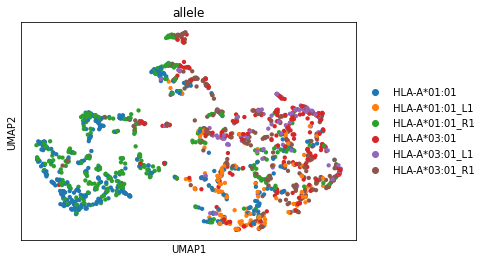

In [750]:
sc.pl.umap(adata_copy, color="allele")

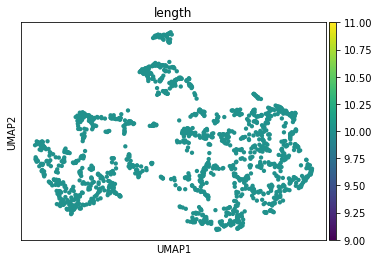

In [751]:
sc.pl.umap(adata_copy, color="length")

<AxesSubplot:xlabel='0', ylabel='1'>

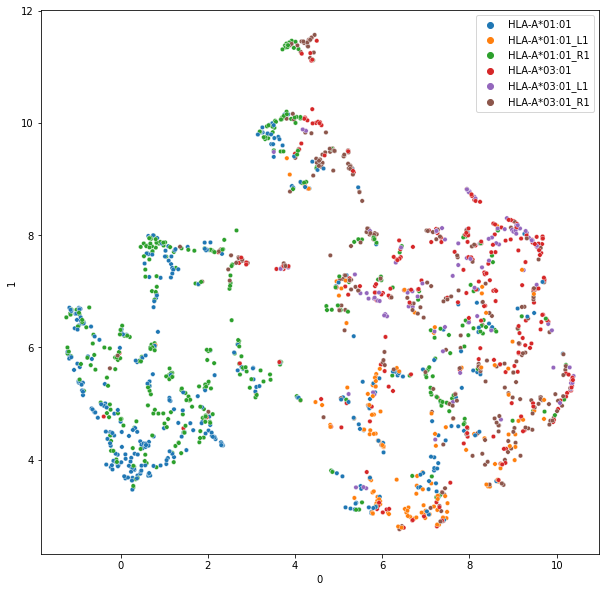

In [752]:
plt.figure(figsize=(10,10))
df = pd.DataFrame(adata_copy.obsm['X_umap'])
sns.scatterplot(data=df, x=0, y=1,s=20, hue=adata_copy.obs['allele'].values)

<AxesSubplot:xlabel='0', ylabel='1'>

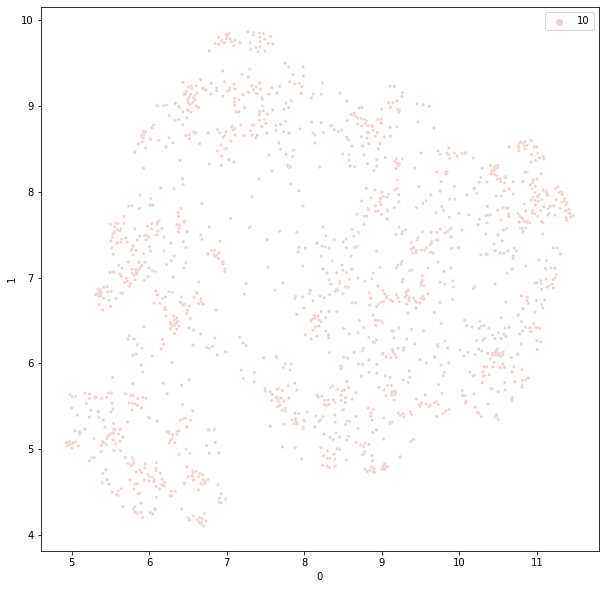

In [727]:
plt.figure(figsize=(10,10))
df = pd.DataFrame(adata_copy.obsm['X_umap'])
sns.scatterplot(data=df, x=0, y=1,s=10, hue=adata_copy.obs['length'].values)

## Color by immunogenicity

In [728]:
adata.obs['immunogenic'] = adata.obs['allele'].str.contains('imm').astype(int)
adata.obs

,peptide,allele,length,leiden,louvain,immunogenic
0,DCTDPYSQMV,HLA-A*01:01_L1,10,5,0,0
1,IQFSMKLLYQ,HLA-A*03:01_R1,10,0,0,0
2,KSDIPMDLFD,HLA-A*01:01,10,3,1,0
3,YPEEVSSMVL,HLA-A*01:01,10,5,0,0
4,TVLKPGNSKM,HLA-A*03:01_R1,10,0,0,0
...,...,...,...,...,...,...
1610,VVAALRASYP,HLA-A*03:01_R1,10,0,0,0
1611,SMQGAVDINR,HLA-A*03:01,10,2,0,0
1612,TSDKGRFYAF,HLA-A*01:01,10,3,1,0
1613,FIDGISLGLK,HLA-A*01:01_R1,10,4,1,0


In [729]:
adata.obs['immunogenic']

0       0
1       0
2       0
3       0
4       0
       ..
1610    0
1611    0
1612    0
1613    0
1614    0
Name: immunogenic, Length: 1615, dtype: int32

<AxesSubplot:xlabel='0', ylabel='1'>

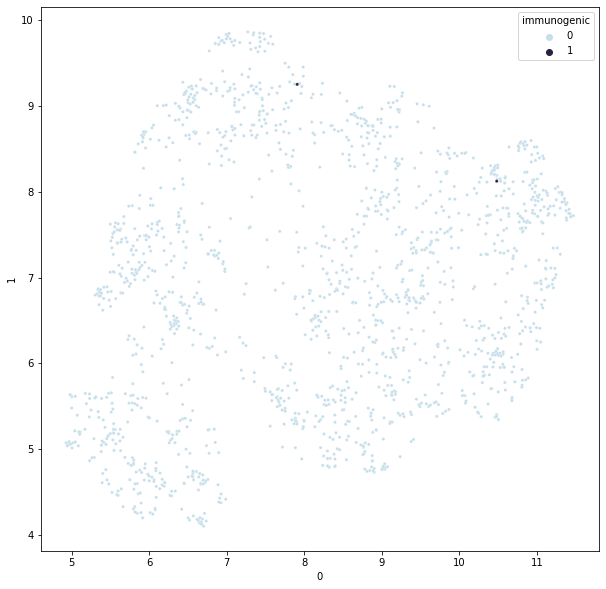

In [730]:
plt.figure(figsize=(10,10))
df = pd.DataFrame(adata.obsm['X_umap']).copy()
df['immunogenic'] = adata.obs['immunogenic'].values
colors = sns.color_palette("ch:s=.25,rot=-.25", 2)
hue_order = [0, 1]
sns.scatterplot(data=df.sort_values(by='immunogenic'), x=0, y=1,s=10, hue='immunogenic', palette=colors, hue_order=hue_order)

## 7. Plot cluster motifs

In [737]:
peptides_df = adata.obs.copy()

In [738]:
counts = dict(peptides_df['allele'].value_counts())
counts = dict(sorted(counts.items()))
# prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
b_counts = [(key,value) if not key.endswith('imm') else (key, 0)for key,value in counts.items() ]
i_counts = [value if key.endswith('imm') else 0 for key,value in counts.items() ]
counts_str = "\n".join([f'{key}: B {b_value}, I {i_value}' for (key,b_value), i_value in zip(b_counts, i_counts)])


In [739]:
b_counts

[('HLA-A*01:01', 377),
 ('HLA-A*01:01_L1', 148),
 ('HLA-A*01:01_R1', 410),
 ('HLA-A*03:01', 264),
 ('HLA-A*03:01_L1', 115),
 ('HLA-A*03:01_R1', 299),
 ('HLA-A*03:01_imm', 0)]

In [740]:
import logomaker
def make_logo(df, length=9, cluster_num=0, ax=None, description_ax=None):
    filtered = df[df['length'] == length]
    if len(filtered) > 0:
        matrix = logomaker.alignment_to_matrix(filtered['peptide'].values)
        info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
        counts = dict(filtered['allele'].value_counts())
        counts = dict(sorted(counts.items()))
        # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
        ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', ax=ax)
        b_counts = [(key,value) if not key.endswith('imm') else (key,0) for key,value in counts.items() ]
        i_counts = [value if key.endswith('imm') else 0 for key,value in counts.items() ]

        counts_str = "\n".join([f'{key}: B {b_value}, I {i_value}' for (key,b_value), i_value in zip(b_counts, i_counts)])
        # if description_ax is not None:
        #     description_ax.text(0.1, 0.1,f'Allele counts:\n {counts_str}', fontsize=9) #add text
        
        print(f"Cluster {cluster_num} \n {counts_str}")
        # counts_str= ""
        ww_logo.ax.set_title(f"Cluster {cluster_num} \n {counts_str}")

In [741]:
def plot_all_cluster_motifs(source_df, cluster_column = 'leiden', target_length=9 ):
    unique_clusters = peptides_df[cluster_column].unique()
    fig, axes = plt.subplots(nrows=len(unique_clusters), ncols=2, figsize=(9,4*len(unique_clusters)))
    for i, cluster_num in enumerate(unique_clusters):
        print(i)
        ax = axes[i, 0]
        df = source_df[source_df[cluster_column] == cluster_num]
        make_logo(df,length=target_length, cluster_num=cluster_num, ax=ax)
        # Additionaly plot immunogenic peptides
        ax = axes[i, 1]
        df = source_df[(source_df[cluster_column] == cluster_num) & (source_df['immunogenic'] == 1)]
        print(len(df))
        if len(df) > 0:
            make_logo(df,length=target_length, cluster_num=cluster_num, ax=ax)
            # Put the legend out of the figure
    plt.tight_layout()
    fig.savefig('temp.png', transparent=False)



0
0
1
0
2
0
3
0
4
1
5
1


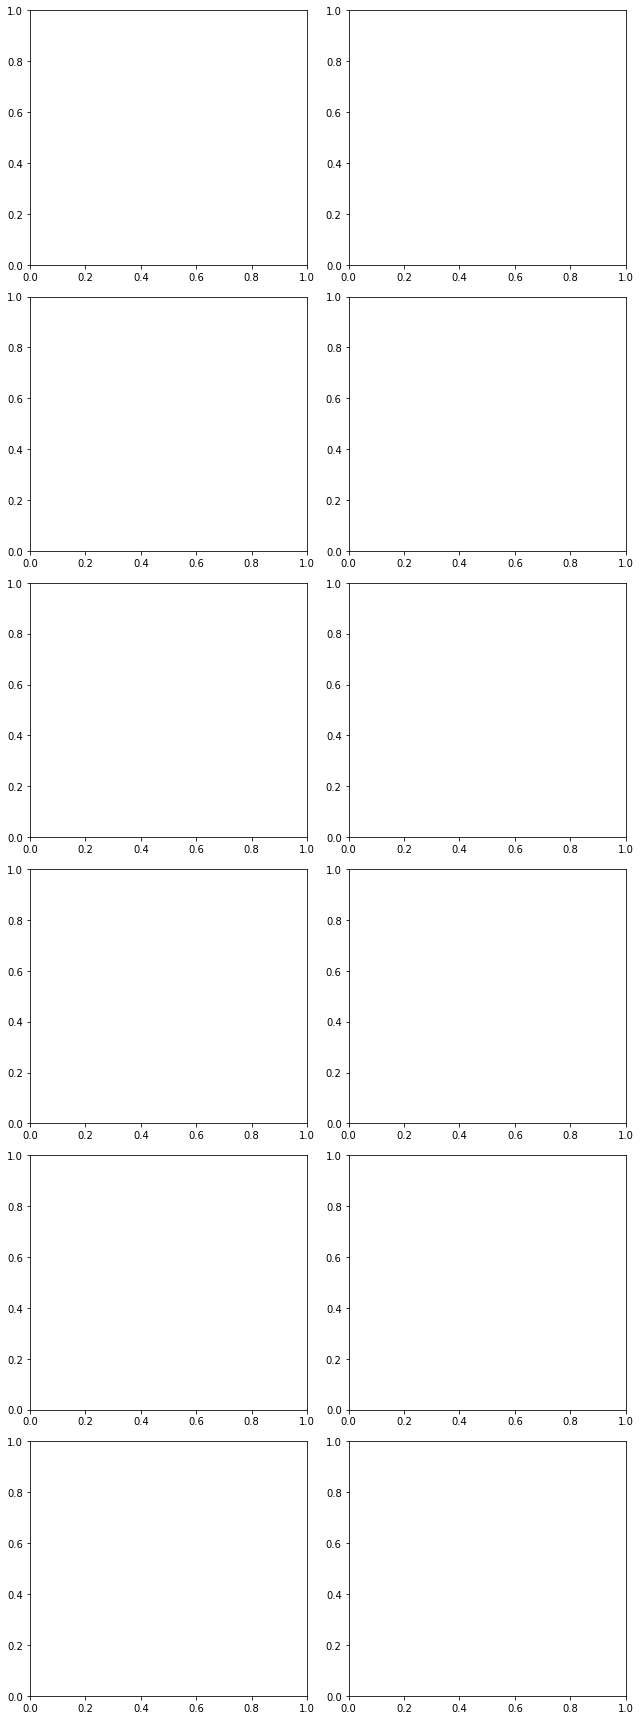

In [742]:
plot_all_cluster_motifs(peptides_df, 'leiden',9)

0
Cluster 5 
 HLA-A*01:01: B 52, I 0
HLA-A*01:01_L1: B 74, I 0
HLA-A*01:01_R1: B 9, I 0
HLA-A*03:01: B 27, I 0
HLA-A*03:01_L1: B 7, I 0
HLA-A*03:01_R1: B 7, I 0
HLA-A*03:01_imm: B 0, I 0
0
1
Cluster 0 
 HLA-A*01:01: B 41, I 0
HLA-A*01:01_L1: B 57, I 0
HLA-A*01:01_R1: B 67, I 0
HLA-A*03:01: B 54, I 0
HLA-A*03:01_L1: B 11, I 0
HLA-A*03:01_R1: B 144, I 0
HLA-A*03:01_imm: B 0, I 0
0
2
Cluster 3 
 HLA-A*01:01: B 65, I 0
HLA-A*01:01_L1: B 5, I 0
HLA-A*01:01_R1: B 103, I 0
HLA-A*03:01: B 19, I 0
HLA-A*03:01_L1: B 4, I 0
HLA-A*03:01_R1: B 40, I 0
HLA-A*03:01_imm: B 0, I 0
0
3
Cluster 4 
 HLA-A*01:01: B 122, I 0
HLA-A*01:01_L1: B 0, I 0
HLA-A*01:01_R1: B 102, I 0
HLA-A*03:01: B 5, I 0
HLA-A*03:01_L1: B 2, I 0
HLA-A*03:01_R1: B 4, I 0
HLA-A*03:01_imm: B 0, I 0
0
4
Cluster 1 
 HLA-A*01:01: B 90, I 0
HLA-A*01:01_L1: B 7, I 0
HLA-A*01:01_R1: B 115, I 0
HLA-A*03:01: B 33, I 0
HLA-A*03:01_L1: B 5, I 0
HLA-A*03:01_R1: B 73, I 0
HLA-A*03:01_imm: B 0, I 1
1
Cluster 1 
 HLA-A*01:01: B 0, I 0
HLA-A*01:01_

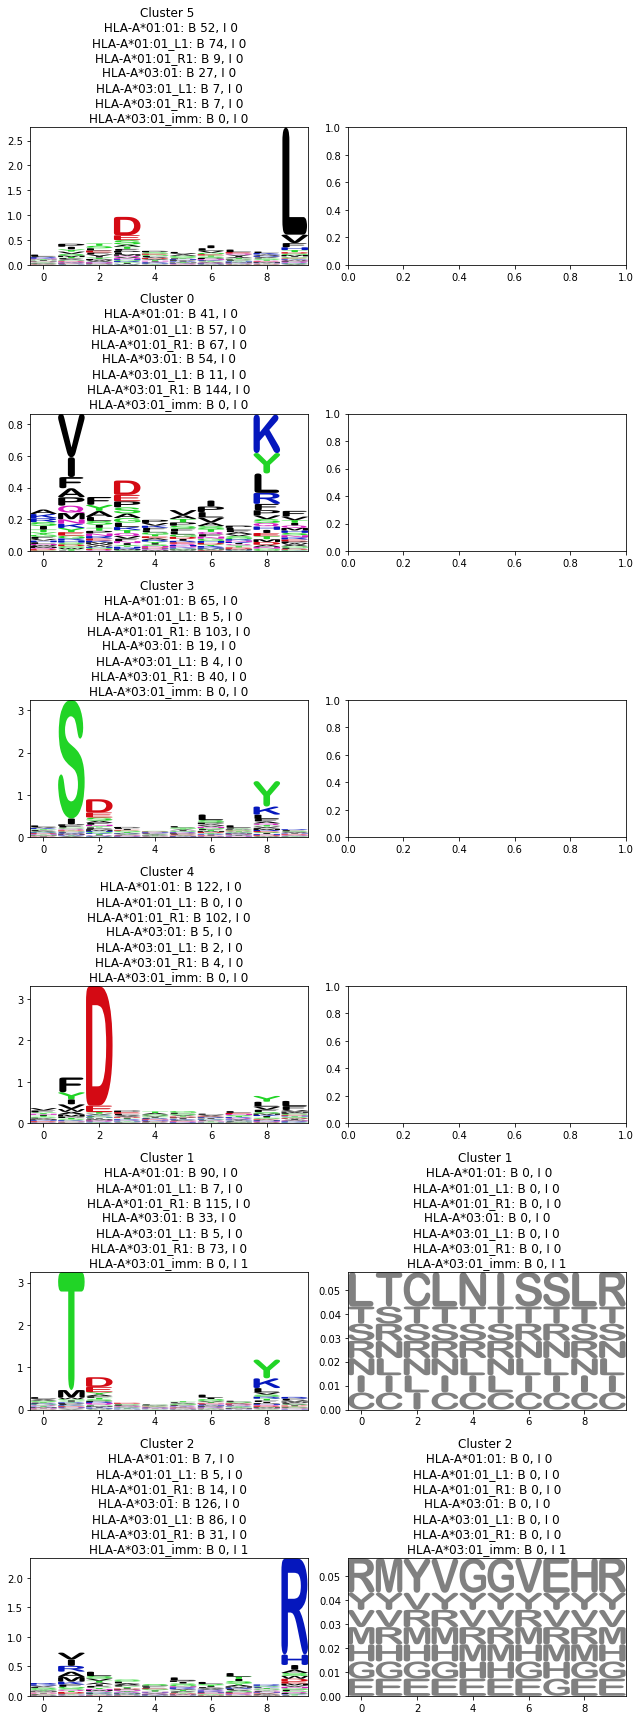

In [743]:
plot_all_cluster_motifs(peptides_df, 'leiden', 10)

0
0
1
0
2
0
3
0
4
1
5
1


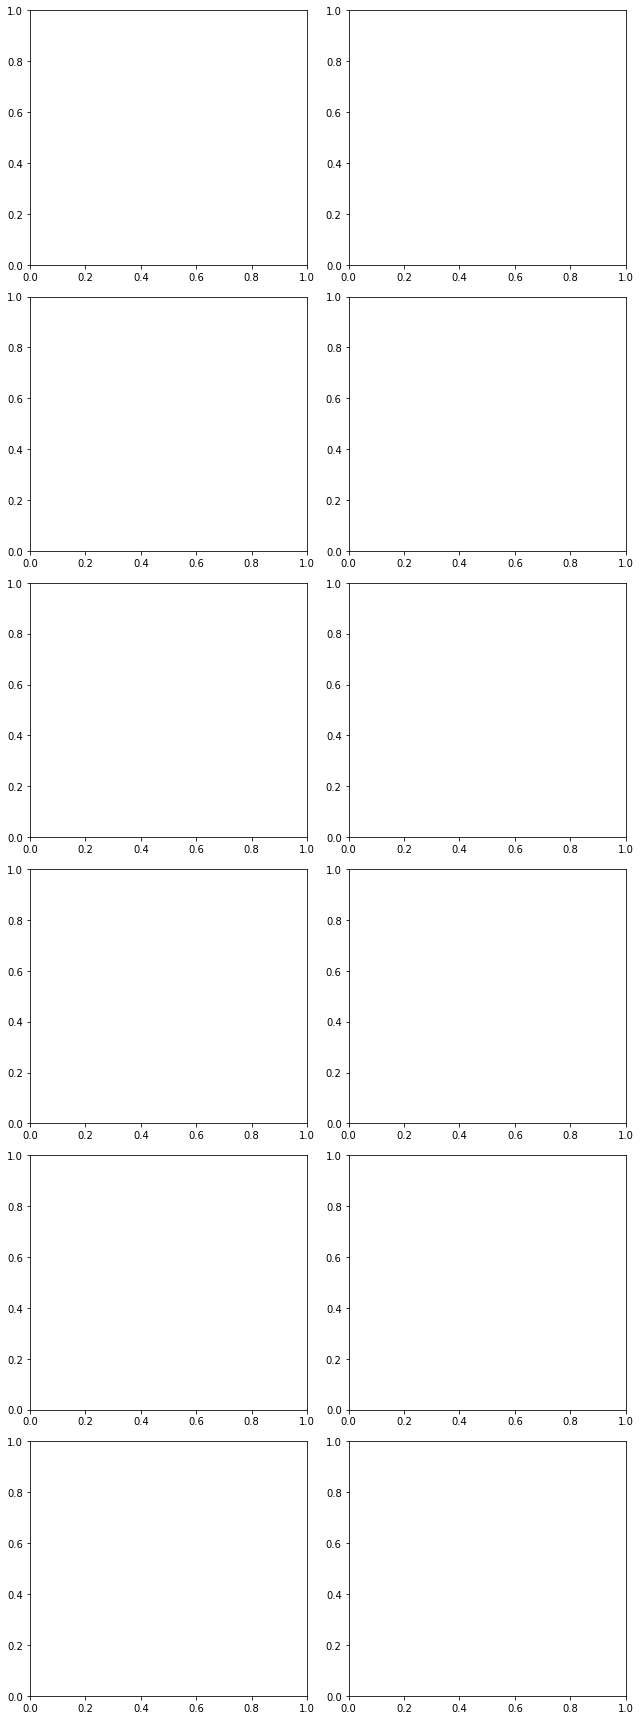

In [744]:
plot_all_cluster_motifs(peptides_df, 'leiden', 11)

In [ ]:
plot_all_cluster_motifs(peptides_df, 'leiden', 12)

In [659]:
selected_peptides = peptides_df[~(peptides_df['leiden'] == '0') ]

In [663]:
selected_peptides = peptides_df[(peptides_df['leiden'] == '0') ]

In [664]:
selected_peptides

,peptide,allele,length,leiden,louvain,immunogenic
1,DCTDPYSQMV,HLA-A*01:01_L1,10,0,1,0
2,IQFSMKLLYQ,HLA-A*03:01_R1,10,0,1,0
4,KSDIPMDLFD,HLA-A*01:01,10,0,1,0
6,YPEEVSSMVL,HLA-A*01:01,10,0,1,0
7,TVLKPGNSKM,HLA-A*03:01_R1,10,0,1,0
...,...,...,...,...,...,...
6311,VVAALRASYP,HLA-A*03:01_R1,10,0,1,0
6313,SMQGAVDINR,HLA-A*03:01,10,0,1,0
6315,TSDKGRFYAF,HLA-A*01:01,10,0,1,0
6321,FIDGISLGLK,HLA-A*01:01_R1,10,0,1,0


## Motif in data

In [53]:
peptides_df['allele'].value_counts()

HLA-A*01:01        2134
HLA-A*03:01        2124
HLA-A*03:01_L1      513
HLA-A*03:01_R1      512
HLA-A*01:01_R1      505
HLA-A*01:01_L1      503
HLA-A*01:01_L2       76
HLA-A*01:01_LR1      76
HLA-A*01:01_R2       76
HLA-A*03:01_imm      26
HLA-A*03:01_L2        9
HLA-A*03:01_LR1       9
HLA-A*03:01_R2        9
HLA-A*01:01_imm       8
Name: allele, dtype: int64

In [73]:
filtered = peptides_df[peptides_df['allele'] == 'HLA-A*03:01_R1'].copy()

512


Text(0.5, 1.0, '512')

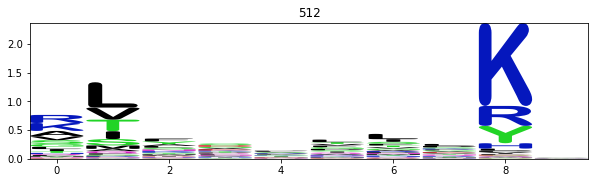

In [74]:
print(len(filtered))
matrix = logomaker.alignment_to_matrix(filtered['peptide'].values)
info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')      
ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold')
ww_logo.ax.set_title(f"{len(filtered)}")

In [60]:
filtered

,peptide,allele,length,leiden,louvain
2,IQFSMKLLYQ,HLA-A*03:01_R1,10,14,1
7,TVLKPGNSKM,HLA-A*03:01_R1,10,0,1
9,RSYSSVIEKK,HLA-A*03:01_R1,10,1,2
16,SLNRVVLKYH,HLA-A*03:01_R1,10,6,3
21,KMWGVLQKKW,HLA-A*03:01_R1,10,0,1
...,...,...,...,...,...
6555,ALWDKTLTHA,HLA-A*03:01_R1,10,6,3
6564,TIYTSYKEKF,HLA-A*03:01_R1,10,0,1
6566,VVAALRASYP,HLA-A*03:01_R1,10,0,1
6572,RVFNNYMPYY,HLA-A*03:01_R1,10,0,1


kk cluster 2

In [43]:
analysis_df = peptides_df[(peptides_df['leiden'] == '2') & (peptides_df['length'] == 10)]

In [44]:
len(analysis_df)

53

In [45]:
analysis_df.head(30)

,peptide,allele,length,leiden,louvain,immunogenic
16,LLYQGVYLKK,HLA-A*03:01,10,2,2,0
141,SLIGYLITKK,HLA-A*03:01,10,2,2,0
378,ILARWSSFKK,HLA-A*03:01,10,2,2,0
628,FLAQALSPKL,HLA-A*03:01,10,2,2,0
909,RLVQGSILKK,HLA-A*03:01,10,2,2,0
1028,ILKRWGQLKK,HLA-A*03:01,10,2,2,0
1055,TLYISECLKK,HLA-A*03:01,10,2,2,0
1184,KLFDFVNAKK,HLA-A*03:01,10,2,2,0
1234,QLCYCPASKK,HLA-A*03:01,10,2,2,0
1235,FLILCFTIKR,HLA-A*03:01,10,2,1,0


In [46]:
analysis_df['peptide'].str.contains('KK$').value_counts()

True     31
False    22
Name: peptide, dtype: int64

In [47]:
analysis_df['peptide'].str.contains('K[^K]$').value_counts()

False    37
True     16
Name: peptide, dtype: int64

In [48]:
analysis_df['peptide'].str.contains('[^K]K$').value_counts()

False    47
True      6
Name: peptide, dtype: int64

kkcluster 1

In [49]:
analysis_df = peptides_df[(peptides_df['leiden'] == '1') & (peptides_df['length'] == 10)]

In [50]:
len(analysis_df)

94

In [51]:
analysis_df['peptide'].str.contains('KK$').value_counts()

False    54
True     40
Name: peptide, dtype: int64

In [52]:
analysis_df['peptide'].str.contains('K[^K]$').value_counts()

False    56
True     38
Name: peptide, dtype: int64

In [53]:
analysis_df['peptide'].str.contains('[^K]K$').value_counts()

False    89
True      5
Name: peptide, dtype: int64

In [62]:
analysis_df.iloc[75:100][['peptide', 'length']]

,peptide,length
5393,KLLDEAIQAV,10
5482,LALEVARQKR,10
5489,RVKLPSGSKK,10
5700,KTIDASVSKK,10
5773,VVLGNIIKKK,10
5922,FVFPLNSKVK,10
5948,KSFPGIPLHH,10
5969,SLRTACVPHR,10
6081,ISWEALRWKA,10
6163,AQYQFTGIKK,10


In [63]:
test_df = analysis_df[~((analysis_df['peptide'].str.contains('[^K]K$')) | 
                         (analysis_df['peptide'].str.contains('K[^K]$')) |
                          (analysis_df['peptide'].str.contains('KK$')))
                         ]

In [64]:
test_df               

,peptide,allele,length,leiden,louvain,immunogenic
167,KLFPGSPAIY,HLA-A*03:01,10,1,1,0
1744,KIDKLTFQIY,HLA-A*03:01,10,1,1,0
2544,KTKDPTAALR,HLA-A*03:01,10,1,0,0
3240,GLLDSIKMIY,HLA-A*03:01,10,1,1,0
3951,LTDFGLSKIM,HLA-A*03:01,10,1,1,0
4159,KLSYGIATVR,HLA-A*03:01,10,1,1,0
4661,ILDDNLYKVY,HLA-A*03:01,10,1,1,0
4945,VTLAILTALR,HLA-A*03:01,10,1,1,0
5393,KLLDEAIQAV,HLA-A*03:01,10,1,1,0
5948,KSFPGIPLHH,HLA-A*03:01,10,1,1,0


In [95]:
target_df.loc['RLNDRYPKKL'].drop(labels=['allele', 'peptide']).astype(float).sort_values(ascending=False).head(20)

98     -0.318822
101    -0.342753
354    -0.368054
2927   -0.383446
2648   -0.384295
0      -0.384449
393    -0.389404
27     -0.394635
151    -0.401635
218    -0.409427
742    -0.410926
390    -0.411313
2858   -0.415922
2667   -0.417967
164    -0.418814
160    -0.421213
3988   -0.429674
135    -0.432491
317    -0.433329
3099   -0.433387
Name: RLNDRYPKKL, dtype: float64

In [66]:
target_df.loc['FLAQALSPKL'][98]

-0.5738168380742605

In [67]:
#0-th model
filename = 'D:\\Projects\\MHC_predictor\\experiments\\length_dependent_hmm\\experiment_results\\alleles_with_groups_single_allele_balanced_data\\0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_03_01-0\\viterbi_paths_df.csv'


In [68]:
df = pd.read_csv(filename, sep=';')

In [124]:
top500 = target_df.loc['RLNDRYPKKL'].drop(labels=['allele', 'peptide']).astype(float).sort_values(ascending=False).head(500).index

In [125]:
top500 = top500[top500.astype(int) < 500].astype(int)

In [126]:
top500

Int64Index([ 98, 101, 354,   0, 393,  27, 151, 218, 390, 164,
            ...
            406, 499, 105, 466, 385, 289, 439, 104, 492,  24],
           dtype='int64', length=143)

In [127]:
df

,path,prob,normalized_prob,len
0,grouped_model-start>s001>s004>s005>s008>s011>s...,-10.010188,-0.910017,9
1,grouped_model-start>s001>s004>s005>s014>s011>s...,-10.110780,-0.919162,9
2,grouped_model-start>s001>s003>s006>s008>s011>s...,-10.163696,-0.923972,9
3,grouped_model-start>s001>s004>s005>s007>s011>s...,-10.232188,-0.930199,9
4,grouped_model-start>s001>s004>s005>s007>s010>s...,-10.290974,-0.935543,9
...,...,...,...,...
708845,grouped_model-start>s003>s006>s014>s010>s014>s...,-32.849135,-2.986285,9
708846,grouped_model-start>s002>s007>s009>s014>s010>s...,-33.048400,-3.004400,9
708847,grouped_model-start>s002>s007>s014>s013>s011>s...,-33.216045,-3.019640,9
708848,grouped_model-start>s000>s008>s009>s006>s005>s...,-36.357856,-3.029821,10


In [129]:
df.loc[top500].len.value_counts()

9     126
10     17
Name: len, dtype: int64

In [76]:
df.loc[98]['path']

'grouped_model-start>s001>s004>s005>s008>s011>s010>s019>s015>s021>grouped_model-end'

In [79]:
df.loc[355]['path']

'grouped_model-start>s001>s004>s005>s014>s010>s012>s016>s019>s021>grouped_model-end'

In [80]:
df['path'][0]

'grouped_model-start>s001>s004>s005>s008>s011>s016>s019>s015>s021>grouped_model-end'

In [81]:
df['path'][:500].str.contains('s021>grouped_model-end').value_counts()

True    500
Name: path, dtype: int64

In [90]:
df['path'].str.contains('s021>grouped_model-end').value_counts()

False    496474
True     212376
Name: path, dtype: int64

In [86]:
df[:500]['len'].value_counts()

9     331
10    169
Name: len, dtype: int64

In [85]:
df.head(50)

,path,prob,normalized_prob,len
0,grouped_model-start>s001>s004>s005>s008>s011>s...,-10.010188,-0.910017,9
1,grouped_model-start>s001>s004>s005>s014>s011>s...,-10.110780,-0.919162,9
2,grouped_model-start>s001>s003>s006>s008>s011>s...,-10.163696,-0.923972,9
3,grouped_model-start>s001>s004>s005>s007>s011>s...,-10.232188,-0.930199,9
4,grouped_model-start>s001>s004>s005>s007>s010>s...,-10.290974,-0.935543,9
5,grouped_model-start>s001>s003>s009>s008>s011>s...,-10.295797,-0.935982,9
6,grouped_model-start>s001>s003>s006>s010>s019>s...,-10.385203,-0.944109,9
7,grouped_model-start>s001>s004>s006>s008>s011>s...,-10.401353,-0.945578,9
8,grouped_model-start>s001>s003>s006>s010>s012>s...,-10.419387,-0.947217,9
9,grouped_model-start>s001>s003>s006>s010>s016>s...,-11.375047,-0.947921,10


In [91]:
no_anchor_at_the_end = df[~df['path'].str.contains('s021>grouped_model-end')]

In [92]:
no_anchor_at_the_end

,path,prob,normalized_prob,len
770,grouped_model-start>s001>s004>s005>s008>s011>s...,-11.619110,-1.056283,9
972,grouped_model-start>s001>s004>s005>s014>s011>s...,-11.719701,-1.065427,9
1069,grouped_model-start>s001>s003>s006>s008>s011>s...,-11.772617,-1.070238,9
1258,grouped_model-start>s001>s004>s005>s007>s011>s...,-11.841109,-1.076464,9
1336,grouped_model-start>s001>s003>s008>s011>s016>s...,-12.953968,-1.079497,10
...,...,...,...,...
708845,grouped_model-start>s003>s006>s014>s010>s014>s...,-32.849135,-2.986285,9
708846,grouped_model-start>s002>s007>s009>s014>s010>s...,-33.048400,-3.004400,9
708847,grouped_model-start>s002>s007>s014>s013>s011>s...,-33.216045,-3.019640,9
708848,grouped_model-start>s000>s008>s009>s006>s005>s...,-36.357856,-3.029821,10


In [193]:
no_anchor_at_the_end.loc[770].path

'grouped_model-start>s001>s004>s005>s008>s011>s016>s019>s015>s024>grouped_model-end'

In [194]:
no_anchor_at_the_end.loc[972].path

'grouped_model-start>s001>s004>s005>s014>s011>s016>s019>s015>s024>grouped_model-end'

In [195]:
no_anchor_at_the_end.loc[1069].path

'grouped_model-start>s001>s003>s006>s008>s011>s016>s019>s015>s024>grouped_model-end'

In [93]:
no_anchor_at_the_end.loc[1258].path

'grouped_model-start>s001>s004>s005>s007>s011>s016>s019>s015>s024>grouped_model-end'

## Motif for 10 mers

In [247]:
df = peptides_df[peptides_df['length'] == 11]
make_logo(df,length=10, cluster_num=0)

In [310]:
peptides_df[peptides_df['peptide'].str.contains("K[^K]$")]

,peptide,allele,length,leiden,louvain,immunogenic
104,RLKGPLLNKR,HLA-A*03:01,10,5,2,0
122,KTSDVVLKR,HLA-A*03:01,9,3,0,0
139,LALEGSLQKR,HLA-A*03:01,10,1,1,0
178,IQNVPLSEKI,HLA-A*03:01,10,1,1,0
269,KSMRDQRKG,HLA-A*03:01,9,0,0,0
...,...,...,...,...,...,...
6113,TVYPVAIKY,HLA-A*03:01,9,0,0,0
6309,RIFVYFITKL,HLA-A*03:01,10,1,1,0
6313,KLYKNKSKQ,HLA-A*03:01,9,4,0,0
6475,VVFGILIKR,HLA-A*03:01,9,0,0,0


### Select metric

In [118]:
metrics = [  'sokalmichener', 'sokalsneath', 'yule', 'cosine', 'euclidean', 'l1', 'l2', 'manhattan','braycurtis', 'canberra', 'chebyshev', 'correlation', 'dice', 'hamming', 'jaccard', 'kulsinski', 'mahalanobis', 'minkowski', 'rogerstanimoto', 'russellrao']

In [ ]:
fig, axes = plt.subplots(nrows=4, ncols=5, figsize=(25,25))
for coord, metric in zip(product(range(5), range(5)), metrics):
    print("metric:", metric , coord)
    sc.pp.neighbors(adata, n_neighbors=30, n_pcs=20, metric=metric)
    sc.tl.umap(adata, min_dist=0.1)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[coord]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"Metric {metric}")

### Select number of principal components

In [120]:
principal_components = range(5, 30, 5)

In [121]:
list(principal_components)

[5, 10, 15, 20, 25]

In [122]:
len(list(principal_components))

5

n_pcs: 5
n_pcs: 10
n_pcs: 15
n_pcs: 20
n_pcs: 25


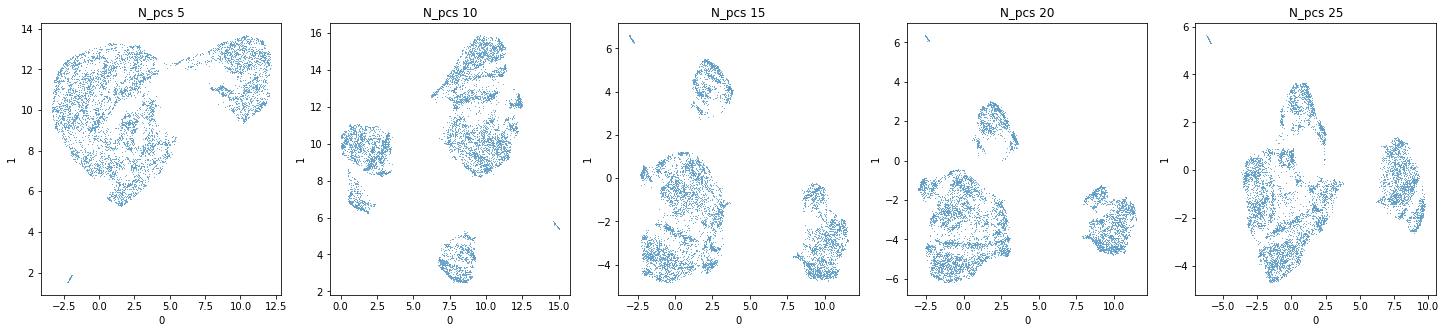

In [123]:
fig, axes = plt.subplots(ncols=5, figsize=(25,5))
for i, n_pcs in enumerate(principal_components):
    print("n_pcs:", n_pcs)
    sc.pp.neighbors(adata, n_neighbors=30, n_pcs=n_pcs, metric='euclidean')
    sc.tl.umap(adata, min_dist=0.1)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[i]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"N_pcs {n_pcs}")

### Select number of neighbours

In [156]:
num_neighbors = range(5, 55, 5)

In [157]:
len(num_neighbors)

10

n_neighbors: 5 (0, 0)
n_neighbors: 10 (0, 1)
n_neighbors: 15 (0, 2)
n_neighbors: 20 (0, 3)
n_neighbors: 25 (0, 4)
n_neighbors: 30 (1, 0)
n_neighbors: 35 (1, 1)
n_neighbors: 40 (1, 2)
n_neighbors: 45 (1, 3)
n_neighbors: 50 (1, 4)


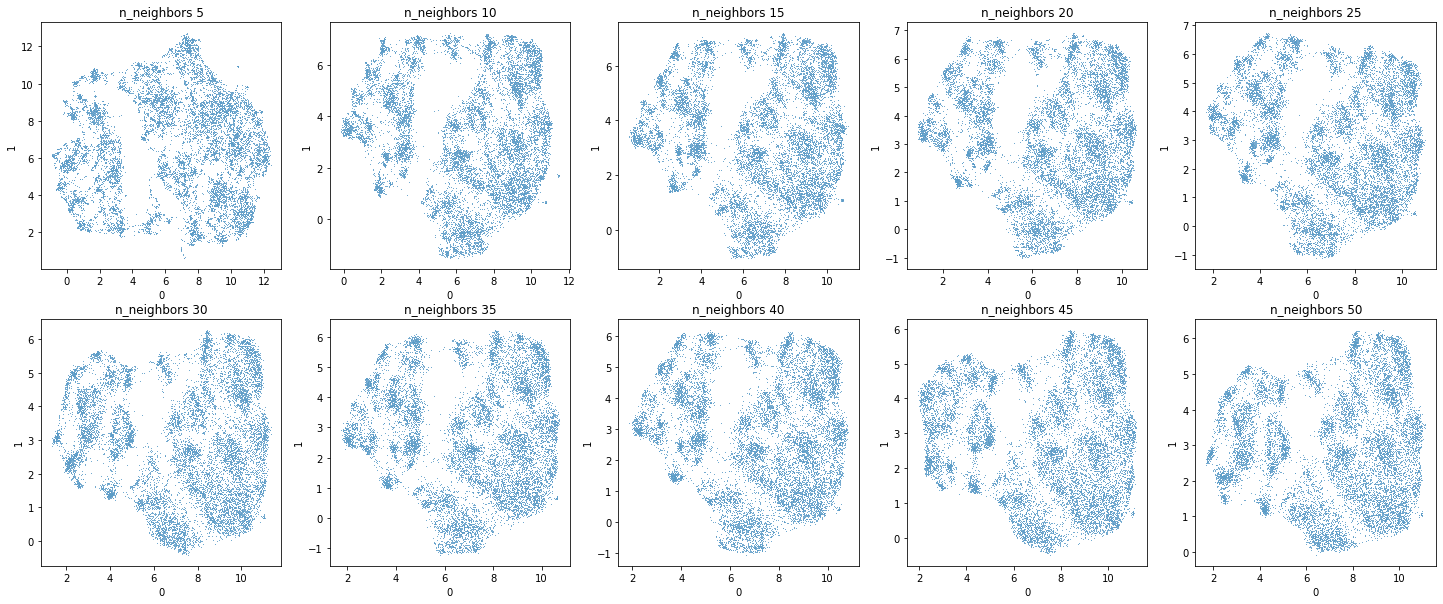

In [158]:
fig, axes = plt.subplots(ncols=5, nrows=2, figsize=(25,10))
for coord, n_neighbors in zip(product(range(2), range(5)), num_neighbors):
    print("n_neighbors:", n_neighbors , coord)
    sc.pp.neighbors(adata, n_neighbors=n_neighbors, n_pcs=20, metric='euclidean')
    sc.tl.umap(adata, min_dist=0.1)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[coord]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"n_neighbors {n_neighbors}")


### Select min_dist

In [159]:
min_dists = np.linspace(0.05, 0.5, 10)

min_dist: 0.05 (0, 0)
min_dist: 0.1 (0, 1)
min_dist: 0.15000000000000002 (0, 2)
min_dist: 0.2 (0, 3)
min_dist: 0.25 (0, 4)
min_dist: 0.3 (1, 0)
min_dist: 0.35000000000000003 (1, 1)
min_dist: 0.4 (1, 2)
min_dist: 0.45 (1, 3)
min_dist: 0.5 (1, 4)


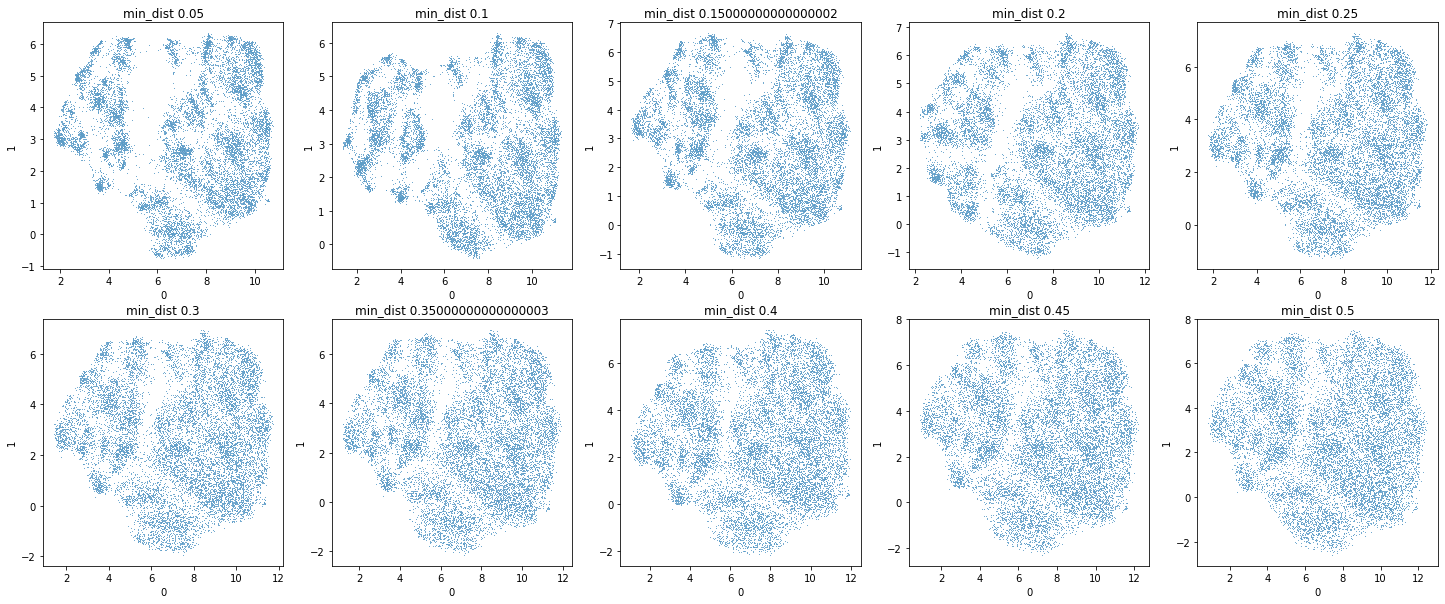

In [160]:
fig, axes = plt.subplots(ncols=5, nrows=2, figsize=(25,10))
for coord, min_dist in zip(product(range(2), range(5)), min_dists):
    print("min_dist:", min_dist , coord)
    sc.pp.neighbors(adata, n_neighbors=30, n_pcs=20, metric='euclidean')
    sc.tl.umap(adata, min_dist=min_dist)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[coord]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"min_dist {min_dist}")